<a href="https://colab.research.google.com/github/arifwinanda22/Arif_Portofolio/blob/main/FinanceFraud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv('Synthetic_Financial_datasets_log.csv')

kolom_fitur = ['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceDest']

df_bersih = df[kolom_fitur + ['nameOrig', 'isFraud']].copy()

print(df_bersih.head())

   step      type    amount  oldbalanceOrg  newbalanceDest     nameOrig  \
0     1   PAYMENT   9839.64       170136.0             0.0  C1231006815   
1     1   PAYMENT   1864.28        21249.0             0.0  C1666544295   
2     1  TRANSFER    181.00          181.0             0.0  C1305486145   
3     1  CASH_OUT    181.00          181.0             0.0   C840083671   
4     1   PAYMENT  11668.14        41554.0             0.0  C2048537720   

   isFraud  
0        0  
1        0  
2        1  
3        1  
4        0  


In [ ]:
print("Memulai proses Data Cleaning...")


print("Jumlah data kosong sebelum dibersihkan:")
print(df_bersih.isnull().sum())


df_bersih.dropna(inplace=True)

jumlah_duplikat = df_bersih.duplicated().sum()
print(f"Ditemukan {jumlah_duplikat} baris duplikat.")

if jumlah_duplikat > 0:
    df_bersih.drop_duplicates(inplace=True)
    print("Data duplikat berhasil dihapus.")

# 3. Memastikan tipe data numerik pada kolom finansial
kolom_finansial = ['amount', 'oldbalanceOrg', 'newbalanceDest'] # Changed 'newbalanceOrig' to 'newbalanceDest'
for kolom in kolom_finansial:
    # Memaksa konversi ke bentuk numerik, nilai yang error akan diubah menjadi NaN lalu dihapus
    df_bersih[kolom] = pd.to_numeric(df_bersih[kolom], errors='coerce')

# Hapus lagi jika ada NaN baru akibat konversi tipe data
df_bersih.dropna(inplace=True)

print("Data Cleaning Selesai. Total baris data saat ini:", len(df_bersih))

Memulai proses Data Cleaning...
Jumlah data kosong sebelum dibersihkan:
step              0
type              0
amount            0
oldbalanceOrg     0
newbalanceDest    0
nameOrig          0
isFraud           0
dtype: int64
Ditemukan 0 baris duplikat.
Data Cleaning Selesai. Total baris data saat ini: 6362620


In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df_bersih['type'] = encoder.fit_transform(df_bersih['type'])

print(f"Kategori transaksi menjadi angka: {encoder.classes_}")

Kategori transaksi menjadi angka: ['CASH_IN' 'CASH_OUT' 'DEBIT' 'PAYMENT' 'TRANSFER']


In [ ]:
kolom_numerik = ['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceDest']

scaler = StandardScaler()

df_bersih[kolom_numerik] = scaler.fit_transform(df_bersih[kolom_numerik])

print("Data setelah dinormalisasi: ")
print(df_bersih[kolom_numerik].head())

Data setelah dinormalisasi: 
       step      type    amount  oldbalanceOrg  newbalanceDest
0 -1.703042  0.952399 -0.281560      -0.229810       -0.333411
1 -1.703042  0.952399 -0.294767      -0.281359       -0.333411
2 -1.703042  1.693076 -0.297555      -0.288654       -0.333411
3 -1.703042 -0.528954 -0.297555      -0.288654       -0.333411
4 -1.703042  0.952399 -0.278532      -0.274329       -0.333411


In [ ]:
grup_nasabah = df_bersih.groupby('nameOrig')

print(f"Total nasabah unik: {len(grup_nasabah)}")

Total nasabah unik: 6353307


In [ ]:
import numpy as np

LANGKAH_WAKTU = 3

# Create a temporary DataFrame for sequence generation
df_seq = df_bersih.copy()

initial_is_fraud_per_customer = df_seq.groupby('nameOrig')['isFraud'].first().rename('customer_is_fraud')

df_seq = df_seq.merge(
    initial_is_fraud_per_customer,
    on='nameOrig',
    how='left'
)

for col in kolom_numerik:
    for i in range(1, LANGKAH_WAKTU):
        df_seq[f'{col}_lag{i}'] = df_seq.groupby('nameOrig')[col].shift(i)

df_seq.dropna(inplace=True)

if df_seq.empty:
    X_data = np.array([])
    y_target = np.array([])
    print("Warning: No complete sequences found after dropping NaNs. X_data and y_target are empty NumPy arrays.")
else:
    feature_arrays_per_timestep = []
    for i in range(LANGKAH_WAKTU - 1, -1, -1):
        current_timestep_cols = []
        if i == 0:
            current_timestep_cols = kolom_numerik
        else:
            current_timestep_cols = [f'{col}_lag{i}' for col in kolom_numerik]
        feature_arrays_per_timestep.append(df_seq[current_timestep_cols].values)


    X_data_temp = np.stack(feature_arrays_per_timestep, axis=0)

    X_data = np.transpose(X_data_temp, (1, 0, 2))
    y_target = df_seq['customer_is_fraud'].values

In [ ]:
# X_data and y_target are already numpy arrays from the previous step
print(f"Ukuran X_data: {X_data.shape}")
print(f"Ukuran y_target: {y_target.shape}")

Ukuran X_data: (15, 3, 5)
Ukuran y_target: (15,)


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

LANGKAH_WAKTU = 3
X_sequences = []
y_target = []

print("Membentuk deret waktu dengan Padding...")

for nama_akun, data_akun in grup_nasabah:
    fitur = data_akun[kolom_numerik].values
    target = data_akun['isFraud'].values

    # Kita tidak lagi membuang yang kurang dari 3
    for i in range(len(fitur)):
        # Ambil dari awal transaksi hingga transaksi saat ini (batas maksimal LANGKAH_WAKTU)
        batas_bawah = max(0, i - LANGKAH_WAKTU + 1)
        potongan = fitur[batas_bawah : i + 1]

        X_sequences.append(potongan)
        y_target.append(target[i]) # Target adalah transaksi pada langkah tersebut

# Melakukan pre-padding: mengisi angka 0 di depan jika transaksi kurang dari 3
X_data = pad_sequences(X_sequences, maxlen=LANGKAH_WAKTU, padding='pre', dtype='float32')
y_target = np.array(y_target)

print("Bentuk matriks X yang baru:", X_data.shape)
print("Bentuk matriks Y yang baru:", y_target.shape)

Membentuk deret waktu dengan Padding...
Bentuk matriks X yang baru: (6362620, 3, 5)
Bentuk matriks Y yang baru: (6362620,)


In [ ]:
from sklearn.model_selection import train_test_split

# Membagi matriks: 80% untuk belajar, 20% untuk ujian akhir
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_target, test_size=0.2, random_state=42
)

print("Dimensi Data Latih (X_train):", X_train.shape)
print("Dimensi Data Uji (X_test):", X_test.shape)

Dimensi Data Latih (X_train): (5090096, 3, 5)
Dimensi Data Uji (X_test): (1272524, 3, 5)


PENGUJIAN LSTM

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Mengambil informasi dimensi dari data latih
langkah_waktu = X_train.shape[1]
jumlah_fitur = X_train.shape[2]

model = Sequential()

# Lapisan LSTM Utama untuk membaca urutan transaksi
model.add(LSTM(units=64, return_sequences=True, input_shape=(langkah_waktu, jumlah_fitur)))
# Lapisan Dropout mematikan 20% neuron secara acak agar model tidak sekadar menghafal
model.add(Dropout(0.2))

# Lapisan LSTM Kedua untuk ekstraksi pola yang lebih dalam
model.add(LSTM(units=32, return_sequences=False))
model.add(Dropout(0.2))

# Lapisan Keputusan (Output) menghasilkan probabilitas 0.0 hingga 1.0
model.add(Dense(units=1, activation='sigmoid'))

# Menampilkan ringkasan struktur model
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 3, 64)          │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,369 (118.63 KB)

 Trainable params: 30,369 (118.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.metrics import AUC, Precision, Recall

model.compile(
    optimizer='adam',
    loss='binary_crossentropy', # Standar kerugian untuk klasifikasi 2 kelas
    metrics=['accuracy', Precision(name='precision'), Recall(name='recall'), AUC(name='auc')]
)
print("Model berhasil dikompilasi dan siap dilatih.")

Model berhasil dikompilasi dan siap dilatih.


In [ ]:
print("Memulai proses pelatihan model...")

# Epochs = berapa kali model mengulang seluruh materi
# Batch size = berapa banyak baris transaksi yang diolah dalam satu waktu
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Memulai proses pelatihan model...
Epoch 1/10
31814/31814 ━━━━━━━━━━━━━━━━━━━━ 322s 10ms/step - accuracy: 0.9992 - auc: 0.8411 - loss: 0.0057 - precision: 0.8628 - recall: 0.4124 - val_accuracy: 0.9993 - val_auc: 0.8812 - val_loss: 0.0036 - val_precision: 0.9535 - val_recall: 0.4782
Epoch 2/10
31814/31814 ━━━━━━━━━━━━━━━━━━━━ 323s 10ms/step - accuracy: 0.9993 - auc: 0.9022 - loss: 0.0034 - precision: 0.9051 - recall: 0.5497 - val_accuracy: 0.9994 - val_auc: 0.9085 - val_loss: 0.0031 - val_precision: 0.9587 - val_recall: 0.5420
Epoch 3/10
31814/31814 ━━━━━━━━━━━━━━━━━━━━ 318s 10ms/step - accuracy: 0.9994 - auc: 0.9215 - loss: 0.0030 - precision: 0.9158 - recall: 0.5832 - val_accuracy: 0.9995 - val_auc: 0.9118 - val_loss: 0.0026 - val_precision: 0.9748 - val_recall: 0.6019
Epoch 4/10
31814/31814 ━━━━━━━━━━━━━━━━━━━━ 316s 10ms/step - accuracy: 0.9994 - auc: 0.9403 - loss: 0.0027 - precision: 0.9245 - recall: 0.6075 - val_accuracy: 0.9994 - val_auc: 0.8967 - val_loss: 0.0029 - val_precision

In [ ]:
# 1. Pengujian Akhir pada Data yang Belum Pernah Dilihat Model
print("\nMelakukan pengujian akhir (Testing)...")
hasil_evaluasi = model.evaluate(X_test, y_test, verbose=1)

# Mencetak hasilnya (urutan metrik sesuai dengan yang di-compile di Tahap 8)
print(f"Loss Akhir: {hasil_evaluasi[0]:.4f}")
print(f"Akurasi: {hasil_evaluasi[1]:.4f}")
print(f"Precision: {hasil_evaluasi[2]:.4f}")
print(f"Recall: {hasil_evaluasi[3]:.4f}")
print(f"AUC: {hasil_evaluasi[4]:.4f}")


Melakukan pengujian akhir (Testing)...
39767/39767 ━━━━━━━━━━━━━━━━━━━━ 107s 3ms/step - accuracy: 0.9995 - auc: 0.9797 - loss: 0.0019 - precision: 0.9503 - recall: 0.6757
Loss Akhir: 0.0019
Akurasi: 0.9995
Precision: 0.9503
Recall: 0.6757
AUC: 0.9797


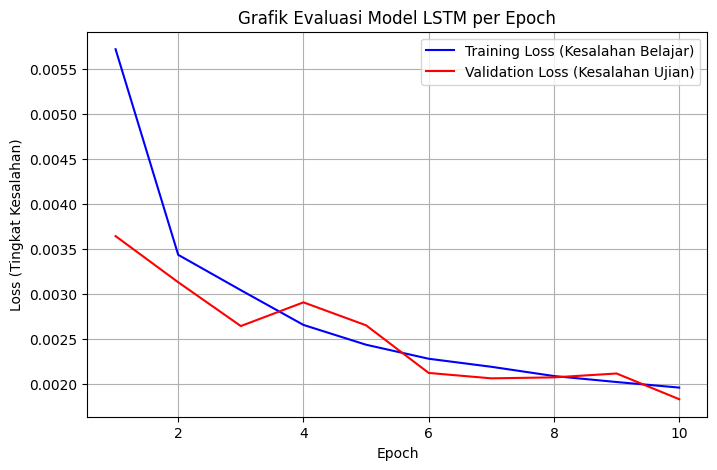

In [ ]:
import matplotlib.pyplot as plt

# Mengambil histori nilai loss selama proses pelatihan
training_loss = history.history['loss']
validation_loss = history.history['val_loss']

# Membuat rentang angka epoch (1 sampai 10)
epochs_range = range(1, len(training_loss) + 1)

# Menggambar grafik
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, training_loss, label='Training Loss (Kesalahan Belajar)', color='blue')
plt.plot(epochs_range, validation_loss, label='Validation Loss (Kesalahan Ujian)', color='red')
plt.title('Grafik Evaluasi Model LSTM per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss (Tingkat Kesalahan)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
model.save('model_deteksi_fraud_lstm.h5')
print("Fail model_deteksi_fraud_lstm.h5 berhasil dibuat dan disimpan!")

Fail model_deteksi_fraud_lstm.h5 berhasil dibuat dan disimpan!


In [ ]:
import time
from sklearn.metrics import recall_score, roc_auc_score, precision_score
from tensorflow.keras.models import load_model
import xgboost as xgb
import numpy as np

# Asumsi: Anda sudah memuat X_test (untuk LSTM bentuk 3D), X_test_xgb (untuk XGB bentuk 2D), dan y_test.

print("Memulai Evaluasi Komparatif...\n")

print("Menyiapkan data untuk XGBoost...")
# Reshape X_data dari (jumlah_sampel, LANGKAH_WAKTU, jumlah_fitur) menjadi (jumlah_sampel, LANGKAH_WAKTU * jumlah_fitur)
X_data_flattened = X_data.reshape(X_data.shape[0], -1)

# Bagi data yang sudah diratakan untuk XGBoost
X_train_xgb, X_test_xgb, y_train_xgb, y_test_xgb = train_test_split(
    X_data_flattened, y_target, test_size=0.2, random_state=42
)

# ==========================================
# 1. EVALUASI XGBOOST
# ==========================================
print("Melatih dan Menguji XGBoost...")

# Inisialisasi model XGBoost
model_xgb = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='aucpr',
    use_label_encoder=False, # Supaya tidak ada warning
    random_state=42
)

# Latih model XGBoost
model_xgb.fit(X_train_xgb, y_train_xgb)

# Simpan model XGBoost setelah dilatih (sehingga bisa dimuat ulang di masa mendatang)
model_xgb.save_model("model_deteksi_fraud_xgboost.json")

waktu_mulai_xgb = time.time()

# Meminta model memprediksi data uji
prediksi_xgb = model_xgb.predict(X_test_xgb)
probabilitas_xgb = model_xgb.predict_proba(X_test_xgb)[:, 1]

# Menghitung total waktu eksekusi
waktu_selesai_xgb = time.time()
durasi_xgb = waktu_selesai_xgb - waktu_mulai_xgb

# ==========================================
# 2. EVALUASI LSTM
# ==========================================
print("Menguji LSTM...")

model_lstm = model # Using the 'model' variable which holds the trained LSTM

waktu_mulai_lstm = time.time()

# LSTM mengeluarkan probabilitas, kita ubah jadi 1 atau 0 (Threshold 0.5)
probabilitas_lstm = model_lstm.predict(X_test)
prediksi_lstm = (probabilitas_lstm > 0.5).astype(int)

# Menghitung total waktu eksekusi
waktu_selesai_lstm = time.time()
durasi_lstm = waktu_selesai_lstm - waktu_mulai_lstm

print("\n" + "="*50)
print("HASIL PERBANDINGAN MODEL (XGBOOST vs LSTM)")
print("="*50)

# Menghitung rata-rata waktu per transaksi (dalam milidetik)
jumlah_transaksi = len(y_test)
ms_per_trx_xgb = (durasi_xgb / jumlah_transaksi) * 1000
ms_per_trx_lstm = (durasi_lstm / jumlah_transaksi) * 1000

print(f"{'Metrik':<20} | {'XGBoost':<12} | {'LSTM':<12}")
print("-" * 50)
print(f"{'Recall (Deteksi Fraud)':<20} | {recall_score(y_test_xgb, prediksi_xgb):.4f}       | {recall_score(y_test, prediksi_lstm):.4f}")
print(f"{'Precision (Ketepatan)':<20} | {precision_score(y_test_xgb, prediksi_xgb):.4f}       | {precision_score(y_test, prediksi_lstm):.4f}")
print(f"{'AUC Score':<20} | {roc_auc_score(y_test_xgb, probabilitas_xgb):.4f}       | {roc_auc_score(y_test, probabilitas_lstm):.4f}")
print(f"{'Waktu Total':<20} | {durasi_xgb:.2f} detik  | {durasi_lstm:.2f} detik")
print(f"{'Kecepatan/Transaksi':<20} | {ms_per_trx_xgb:.4f} ms    | {ms_per_trx_lstm:.4f} ms")
print("=" * 50)

Memulai Evaluasi Komparatif...

Menyiapkan data untuk XGBoost...
Melatih dan Menguji XGBoost...


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [08:35:20] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Menguji LSTM...
39767/39767 ━━━━━━━━━━━━━━━━━━━━ 84s 2ms/step

HASIL PERBANDINGAN MODEL (XGBOOST vs LSTM)
Metrik               | XGBoost      | LSTM        
--------------------------------------------------
Recall (Deteksi Fraud) | 0.2140       | 0.6757
Precision (Ketepatan) | 0.2258       | 0.9503
AUC Score            | 0.6413       | 0.9968
Waktu Total          | 4.96 detik  | 112.19 detik
Kecepatan/Transaksi  | 0.0039 ms    | 0.0882 ms


Menghasilkan grafik perbandingan...


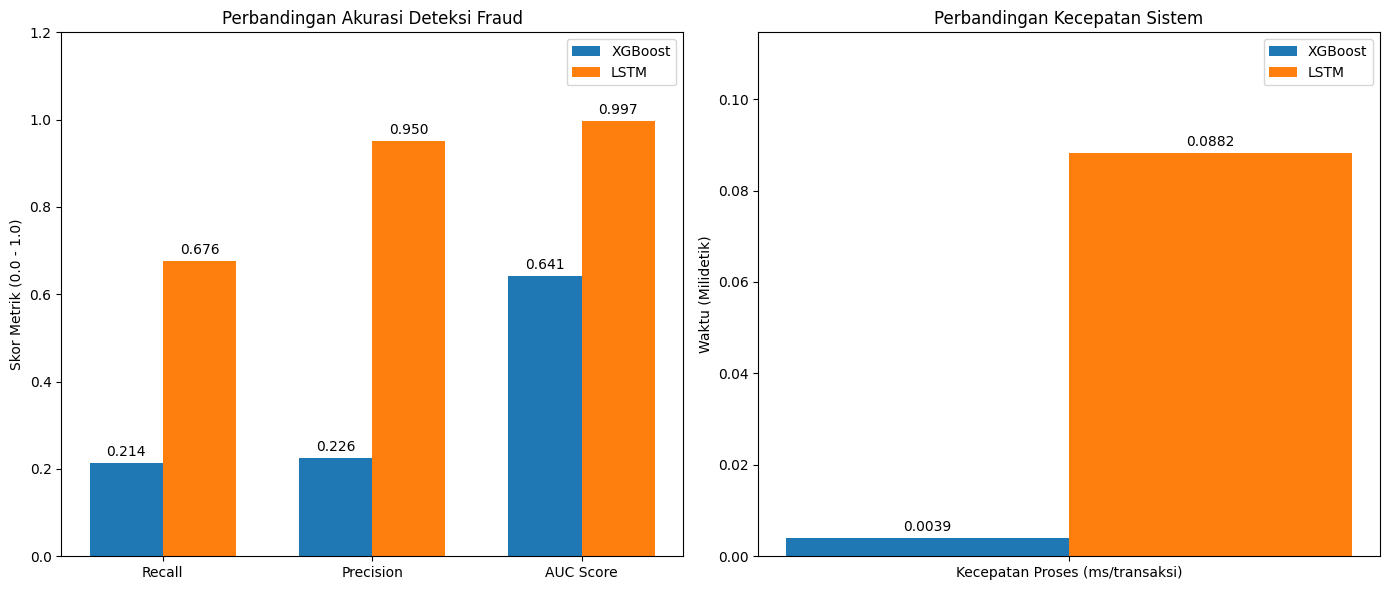

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

print("Menghasilkan grafik perbandingan...")

# Menyiapkan data metrik performa (skala 0.0 - 1.0)
labels_performa = ['Recall', 'Precision', 'AUC Score']
nilai_xgb_performa = [
    recall_score(y_test, prediksi_xgb),
    precision_score(y_test, prediksi_xgb),
    roc_auc_score(y_test, probabilitas_xgb)
]
nilai_lstm_performa = [
    recall_score(y_test, prediksi_lstm),
    precision_score(y_test, prediksi_lstm),
    roc_auc_score(y_test, probabilitas_lstm)
]

# Mengatur posisi letak bar pada grafik
x = np.arange(len(labels_performa))
lebar_bar = 0.35

# Membuka kanvas gambar dengan 2 bagian (kiri untuk performa, kanan untuk kecepatan)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- BAGIAN 1: GRAFIK KINERJA ---
bar1 = ax1.bar(x - lebar_bar/2, nilai_xgb_performa, lebar_bar, label='XGBoost', color='#1f77b4')
bar2 = ax1.bar(x + lebar_bar/2, nilai_lstm_performa, lebar_bar, label='LSTM', color='#ff7f0e')

ax1.set_ylabel('Skor Metrik (0.0 - 1.0)')
ax1.set_title('Perbandingan Akurasi Deteksi Fraud')
ax1.set_xticks(x)
ax1.set_xticklabels(labels_performa)
ax1.legend()
ax1.set_ylim(0, 1.2) # Memberi ruang agar teks tidak terpotong

# Menempelkan angka tepat di atas bar grafik kinerja
ax1.bar_label(bar1, fmt='%.3f', padding=3)
ax1.bar_label(bar2, fmt='%.3f', padding=3)


# --- BAGIAN 2: GRAFIK KECEPATAN INFERENSI ---
labels_waktu = ['Kecepatan Proses (ms/transaksi)']
nilai_xgb_waktu = [ms_per_trx_xgb]
nilai_lstm_waktu = [ms_per_trx_lstm]

x_waktu = np.arange(len(labels_waktu))

bar3 = ax2.bar(x_waktu - lebar_bar/2, nilai_xgb_waktu, lebar_bar, label='XGBoost', color='#1f77b4')
bar4 = ax2.bar(x_waktu + lebar_bar/2, nilai_lstm_waktu, lebar_bar, label='LSTM', color='#ff7f0e')

ax2.set_ylabel('Waktu (Milidetik)')
ax2.set_title('Perbandingan Kecepatan Sistem')
ax2.set_xticks(x_waktu)
ax2.set_xticklabels(labels_waktu)
ax2.legend()
ax2.set_ylim(0, max(ms_per_trx_xgb, ms_per_trx_lstm) * 1.3)

# Menempelkan angka tepat di atas bar grafik waktu
ax2.bar_label(bar3, fmt='%.4f', padding=3)
ax2.bar_label(bar4, fmt='%.4f', padding=3)

# Merapikan dan menampilkan grafik
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

print("Mengambil 100 transaksi acak dari data uji LSTM...\n")

jumlah_data_uji = X_test.shape[0]
indeks_acak = np.random.choice(jumlah_data_uji, size=100, replace=False)

sampel_X_lstm = X_test[indeks_acak]
status_asli_lstm = y_test[indeks_acak]

skor_mentah = model_lstm.predict(sampel_X_lstm, verbose=0).flatten()



def sigmoid(x):
  # Mencegah overflow pada exponential jika angka terlalu besar/kecil
  x = np.clip(x, -500, 500)
  return 1 / (1 + np.exp(-x))


skor_probabilitas_lstm = sigmoid(skor_mentah)


keputusan_klasifikasi_lstm = (skor_probabilitas_lstm > 0.5).astype(int)


tabel_hasil_lstm = pd.DataFrame({
    'Skor Keyakinan AI (LSTM)': skor_probabilitas_lstm,
    'Keputusan Model': keputusan_klasifikasi_lstm,
    'Status Asli (Kunci)': status_asli_lstm,
})


tabel_hasil_lstm['Tindakan Sistem'] = tabel_hasil_lstm['Keputusan Model'].map(
    {0: 'Loloskan (Normal)', 1: 'Blokir (Fraud)'}
)

print('--- BUKTI PROSES KLASIFIKASI LSTM ---')
print(tabel_hasil_lstm.to_string(index=False))

Mengambil 100 transaksi acak dari data uji LSTM...

--- BUKTI PROSES KLASIFIKASI LSTM ---
 Skor Keyakinan AI (LSTM)  Keputusan Model  Status Asli (Kunci)   Tindakan Sistem
                 0.500000                1                    0    Blokir (Fraud)
                 0.500000                1                    0    Blokir (Fraud)
                 0.500000                1                    0    Blokir (Fraud)
                 0.500000                0                    0 Loloskan (Normal)
                 0.500000                1                    0    Blokir (Fraud)
                 0.500000                1                    0    Blokir (Fraud)
                 0.500000                0                    0 Loloskan (Normal)
                 0.500000                0                    0 Loloskan (Normal)
                 0.500015                1                    0    Blokir (Fraud)
                 0.500001                1                    0    Blokir (Fraud)
        

In [ ]:
model.save('model_deteksi_fraud_lstm.h5')
print("Fail model_deteksi_fraud_lstm.h5 berhasil dibuat dan disimpan!")

Fail model_deteksi_fraud_lstm.h5 berhasil dibuat dan disimpan!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve

# 1. Generate Prediction
y_pred_prob = model_lstm.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# 2. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"],
)
plt.title("Confusion Matrix - sentinelPay AI Engine")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.close()

# 3. Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_pred_prob)
plt.figure(figsize=(6, 4))
plt.plot(recall, precision, color="#059669", lw=2, label="LSTM Model")
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("precision_recall_curve.png")
plt.close()

# 4. Print Detail Classification Report
print("\n--- Detail Evaluasi Model ---")
print(classification_report(y_test, y_pred, target_names=["Normal", "Fraud"]))

39767/39767 ━━━━━━━━━━━━━━━━━━━━ 83s 2ms/step

--- Detail Evaluasi Model ---
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00   1270856
       Fraud       0.95      0.68      0.79      1668

    accuracy                           1.00   1272524
   macro avg       0.97      0.84      0.89   1272524
weighted avg       1.00      1.00      1.00   1272524

